# Drones Ukraine v2 : 1. Génération de trajectoires cohérentes

Ce notebook complète la v1 (notebooks R `1 - generationTrajectoires` et `2 - classificationTrajectoires`, inchangés à la racine du dépôt). Il simule des vols de drones russes et ukrainiens à partir de caractéristiques publiques (OSINT), puis leur observation par un réseau radar.

**Ce qui change par rapport à la v1**

| Aspect | v1 | v2 |
|---|---|---|
| Modèles | 4 (Shahed 136, Orlan 10, Babor, Valkyrie) | 12 modèles employés dans la guerre, 4 rôles |
| Paramètres | valeurs fixes par classe | fourchettes publiées, tirées vol par vol (recouvrements réalistes) |
| Trajectoires | segments droits base vers cible | routes programmées (détours, feintes, couloirs), motifs de patrouille, orbites de recherche, piqué terminal |
| Contexte | aucun | raids mixtes avec leurres, vent du jour, défense adverse (abattu, brouillé) |
| Observation | positions exactes | radar : portée limitée par l'horizon et la SER, bruit de mesure, pistes fragmentées |
| Vitesse, altitude | tirées selon la classe (séparation parfaite) | mesurées sur la piste radar bruitée |

**Avertissement.** Données synthétiques. Les caractéristiques publiques sont des ordres de grandeur (les sources divergent), la ligne de front est simplifiée et les positions radar sont fictives. Les résultats mesurent la capacité des méthodes sur ce simulateur, pas une performance opérationnelle.

In [1]:
import sys
import warnings
from pathlib import Path

# Le notebook s'exécute depuis le dossier v2 (ou depuis la racine du dépôt).
RACINE_V2 = Path.cwd() if (Path.cwd() / "drone_v2").exists() else Path.cwd() / "v2"
sys.path.insert(0, str(RACINE_V2))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from drone_v2 import config, viz

viz.appliquer_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}".replace(",", " "))
%matplotlib inline

from drone_v2 import catalogue as cat
from drone_v2 import donnees
from drone_v2.geo import Theatre
from drone_v2.radar import ReseauRadar

## 1. Catalogue OSINT des drones

Chaque modèle combine des **valeurs publiées** (vitesse de croisière, vitesse maximale, plafond, portée, endurance) et des **hypothèses de simulation** (préfixe `hyp_`) lorsqu'aucune valeur publique fiable n'existe : bande d'altitude d'emploi, surface équivalente radar (SER), durée typique de mission. Le tableau complet, URL des sources comprises, est enregistré dans `data/referentiels/catalogue_drones_v2.csv`.

In [2]:
catalogue = cat.catalogue_df()
catalogue.to_csv(config.REFERENTIELS / "catalogue_drones_v2.csv", index=False)
publie = ["modele", "origine", "role", "v_croisiere_min", "v_croisiere_max", "v_max", "alt_min", "alt_max",
          "portee_km", "endurance_h", "sources"]
display(catalogue[publie])

,modele,origine,role,v_croisiere_min,v_croisiere_max,v_max,alt_min,alt_max,portee_km,endurance_h,sources
0,Shahed-136 (Geran-2),Russie,Frappe longue portée,150,185,210,60.000,4 000.000,2000,12.000,WIKI_SHAHED;GS_GERAN2;GUR_GERAN2;BI_SHAHED_ALT...
1,Gerbera,Russie,Leurre,90,130,160,100.000,3 000.000,600,NaN,WIKI_GERBERA;GUR_GERBERA;CAPSS_GERBERA;ISIS_LE...
2,Lancet-3,Russie,Munition rôdeuse,80,110,300,NaN,NaN,40,1.000,WIKI_LANCET;GS_LANCET
3,Orlan-10,Russie,Reconnaissance,90,120,150,NaN,5 000.000,120,16.000,GS_ORLAN10;WIKI_ORLAN10
4,Supercam S350,Russie,Reconnaissance,75,120,120,150.000,5 000.000,100,4.500,GUR_S350
5,An-196 Liutyi,Ukraine,Frappe longue portée,150,200,200,NaN,NaN,2000,NaN,WIKI_LIUTYI
6,UJ-26 Bober (Babor v1),Ukraine,Frappe longue portée,120,200,200,NaN,NaN,1000,7.000,WIKI_BOBER;NV_BOBER
7,UJ-22 Airborne,Ukraine,Frappe longue portée,120,140,160,50.000,6 000.000,800,7.000,GS_UJ22
8,Warmate,Ukraine,Munition rôdeuse,80,120,150,NaN,NaN,30,1.000,WIKI_WARMATE
9,Leleka-100,Ukraine,Reconnaissance,65,80,100,NaN,1 500.000,45,2.500,AT_LELEKA;USS_LELEKA


In [3]:
hypotheses = ["modele", "hyp_alt_basse", "hyp_alt_haute", "hyp_part_haute", "hyp_v_pique", "hyp_ser_m2",
              "hyp_duree_mission_h", "hyp_rayon_km", "note"]
display(catalogue[hypotheses])

,modele,hyp_alt_basse,hyp_alt_haute,hyp_part_haute,hyp_v_pique,hyp_ser_m2,hyp_duree_mission_h,hyp_rayon_km,note
0,Shahed-136 (Geran-2),100-600,1500-3000,0.600,250.000,0.500,,NaN,"Croisière 150-185 km/h, bande 60-4000 m ; vol ..."
1,Gerbera,300-1200,1500-2800,0.400,NaN,0.500,,NaN,"Leurre en mousse et contreplaqué, croisière ~9..."
2,Lancet-3,200-1200,,0.000,300.000,0.030,0.3-0.67,40.000,"Croisière 80-110 km/h, piqué jusqu'à 300 km/h,..."
3,Orlan-10,800-2500,,0.000,NaN,0.080,2.0-6.0,110.000,"Vitesse max 150 km/h, plafond ~5000 m, enduran..."
4,Supercam S350,400-2500,,0.000,NaN,0.060,1.5-4.0,80.000,"65-120 km/h, endurance ~4,5 h, liaison radio 7..."
5,An-196 Liutyi,100-800,1500-3000,0.300,230.000,0.800,,NaN,Portée 1000-2000 km publiée ; vitesse non offi...
6,UJ-26 Bober (Babor v1),50-600,,0.000,220.000,0.300,,NaN,"Portée 600-1000 km, vitesse 120-200 km/h non v..."
7,UJ-22 Airborne,300-1500,2000-4000,0.400,200.000,0.400,,NaN,"Croisière 120-140 km/h, max 160 km/h, plafond ..."
8,Warmate,150-1000,,0.000,150.000,0.020,0.3-1.0,30.000,"Croisière 80-120 km/h, piqué 150 km/h, portée ..."
9,Leleka-100,300-1400,,0.000,NaN,0.020,1.0-2.3,40.000,"Croisière 70-75 km/h, plafond 1500 m, 2,5 h d'..."


In [4]:
display(Markdown("**Sources**\n\n" + "\n".join(f"* `{k}` : {v}" for k, v in cat.SOURCES.items())))

**Sources**

* `WIKI_SHAHED` : https://en.wikipedia.org/wiki/HESA_Shahed_136
* `GS_GERAN2` : https://www.globalsecurity.org/military/world/russia/geran-2.html
* `GUR_GERAN2` : https://war-sanctions.gur.gov.ua/en/uav/336
* `BI_SHAHED_ALT` : https://www.yahoo.com/news/russia-drone-tactic-dive-bombing-060045080.html
* `EMP_SHAHED_2025` : https://euromaidanpress.com/2025/06/29/why-cant-ukraine-stop-russias-shahed-drones-anymore/
* `WIKI_GERBERA` : https://en.wikipedia.org/wiki/Gerbera_(drone)
* `GUR_GERBERA` : https://war-sanctions.gur.gov.ua/en/uav/329
* `CAPSS_GERBERA` : https://capssindia.org/?p=16521
* `ISIS_LEURRES` : https://isis-online.org/isis-reports/a-comprehensive-analytical-review-of-russian-shahed-type-uavs-deployment-against-ukraine-in-2025
* `WIKI_LANCET` : https://en.wikipedia.org/wiki/ZALA_Lancet
* `GS_LANCET` : https://www.globalsecurity.org/military/world/russia/lancet-specs.htm
* `GS_ORLAN10` : https://www.globalsecurity.org/military/world/russia/orlan-10-specs.htm
* `WIKI_ORLAN10` : https://en.wikipedia.org/wiki/Orlan-10
* `GUR_S350` : https://war-sanctions.gur.gov.ua/en/uav/217
* `WIKI_LIUTYI` : https://en.wikipedia.org/wiki/Liutyi
* `WIKI_BOBER` : https://en.wikipedia.org/wiki/Bober_(drone)
* `NV_BOBER` : https://english.nv.ua/nation/uj-26-bober-the-drone-hitting-deep-inside-russia-50619436.html
* `GS_UJ22` : https://www.globalsecurity.org/military/world/ukraine/uj-22-specs.htm
* `WIKI_WARMATE` : https://en.wikipedia.org/wiki/WB_Electronics_Warmate
* `AT_LELEKA` : https://www.army-technology.com/projects/leleka-100-unmanned-aerial-vehicle-uav-ukraine/
* `USS_LELEKA` : https://ukrspecsystems.com/drones/leleka-100-electric-uav
* `GS_FURIA` : https://www.globalsecurity.org/military/world/ukraine/furia-uav.htm
* `MSPO_FURIA` : https://www.targikielce.pl/en/mspo/list-of-exhibitors/athlon-avia,3818965
* `MVS_VALKYRIA` : https://mvs.gov.ua/en/news/u-tilu-voroga-prikordonniki-vikonuiut-zavdannia-zavdiaki-bezpilotnomu-kompleksu-valkiriia-video
* `UP_VALKYRIA` : https://www.pravda.com.ua/eng/news/2026/02/04/8019364

## 2. Théâtre d'opérations

* **Frontières** : Natural Earth 1:50m. Natural Earth rattache la Crimée à la Russie ; elle est ici rattachée à l'Ukraine (frontières internationalement reconnues) et classée en territoire occupé.
* **Ligne de contact** : tracé simplifié inspiré des cartes publiques de 2025, précision de l'ordre de 10 à 20 km, prolongé par la frontière russo-ukrainienne au nord.
* **Sites de lancement russes** : sites cités dans les bilans de l'armée de l'air ukrainienne et les analyses OSINT (ISIS, Militarnyi, Censor.net...).
* **Zones de lancement ukrainiennes et radars** : positions fictives tirées au hasard ; aucune donnée sensible n'est utilisée.

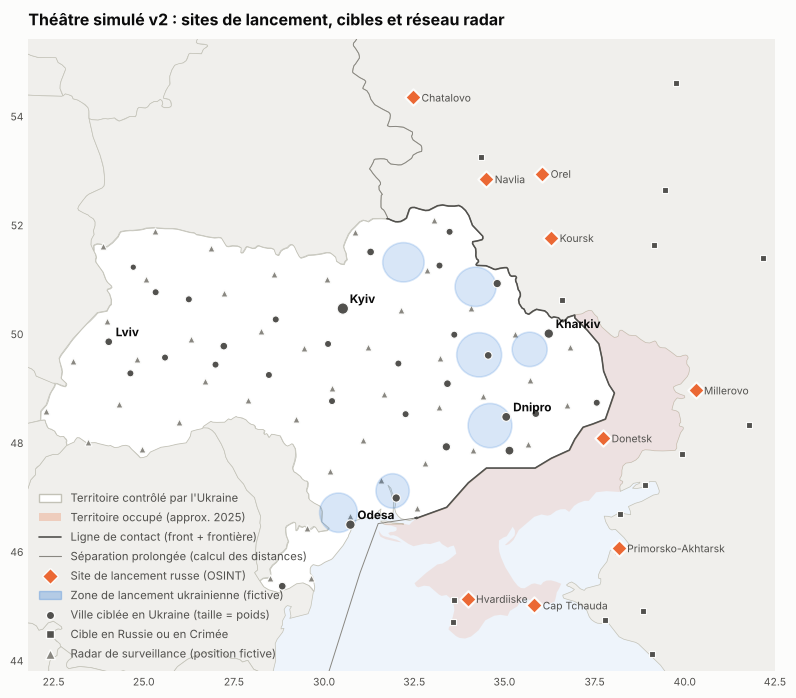

47 radars fictifs ; ligne de contact simplifiée de 1325 km


In [5]:
theatre = Theatre()
radar = ReseauRadar(theatre)
R = config.REFERENTIELS
sites_ru = pd.read_csv(R / "sites_lancement_russes_v2.csv")
zones_ua = pd.read_csv(R / "zones_lancement_ukrainiennes_v2.csv")
cibles_ua = pd.read_csv(R / "cibles_ukraine_v2.csv")
cibles_ru = pd.read_csv(R / "cibles_russie_v2.csv")
fig = viz.fig_theatre(theatre, sites_ru, zones_ua, cibles_ua, cibles_ru, radar.table_sites())
viz.sauver(fig, "01_theatre_v2")
plt.show()
print(f"{len(radar.sites)} radars fictifs ; ligne de contact simplifiée de {theatre.ligne_contact_xy.length / 1000:.0f} km")

## 3. Règles de simulation

Les profils de mission reprennent l'emploi documenté de chaque famille de drones.

* **Frappe longue portée** (Shahed-136, An-196 Liutyi, UJ-26 Bober, UJ-22) : raids nocturnes par groupes ; route programmée par points de passage avec détour lissé, couloirs (le long de la frontière biélorusse, au-dessus de la mer Noire), feinte dans 20 % des groupes ; vol bas (100 à 600 m) ou haut (1 500 à 3 000 m, tendance observée en 2025) ; changements de palier ; piqué terminal.
* **Leurre** (Gerbera) : 30 à 55 % des drones d'un raid russe ; suit la route du groupe puis s'en écarte, orbite parfois au-dessus d'une zone, vole jusqu'à épuisement du carburant (portée de 300 à 600 km).
* **Munition rôdeuse** (Lancet-3, Warmate) : lancement à quelques kilomètres derrière la ligne de contact, orbites de recherche au-delà, piqué.
* **Reconnaissance** (Orlan-10, Supercam S350, Leleka-100, A1-SM Furia, Valkyria) : transit, motif de patrouille (hippodrome, orbite, balayage, points d'intérêt) dans le rayon d'action publié, retour et atterrissage.
* **Environnement** : vent quotidien (il modifie la vitesse sol ; une sortie tactique est annulée si le vent dépasse 60 % de la vitesse air) ; défense adverse qui abat ou brouille les drones selon la distance parcourue en territoire ennemi.
* **Reproductibilité** : chaque vol possède son propre générateur aléatoire dérivé de la graine globale ; deux exécutions produisent exactement les mêmes données.

La simulation complète (120 jours, observation radar et calcul des variables) prend environ deux minutes.

In [6]:
d = donnees.generer()
resume, pistes, plots, variables = d["resume"], d["pistes"], d["plots"], d["variables"]

jour 0 : 75 vols


jour 20 : 1448 vols


jour 40 : 2742 vols


jour 60 : 3974 vols


jour 80 : 5028 vols


jour 100 : 6180 vols


7302 vols simulés en 35 s


7558 pistes radar, 4281777 plots (65 s)


Variables calculées (172 s)


In [7]:
synthese = (resume.groupby(["role", "origine"])
            .agg(vols=("drone_id", "size"), duree_mediane_min=("duree_min", "median"),
                 distance_mediane_km=("distance_km", "median"), vitesse_mediane_kmh=("v_croisiere_kmh", "median"))
            .reset_index())
display(synthese)
n_plots = f"{len(plots):,}".replace(",", " ")
print(f"{len(resume)} vols simulés, {len(pistes)} pistes radar, {n_plots} plots radar")

,role,origine,vols,duree_mediane_min,distance_mediane_km,vitesse_mediane_kmh
0,Frappe longue portée,Russie,1885,135.833,368.779,167.921
1,Frappe longue portée,Ukraine,700,136.583,348.154,159.602
2,Leurre,Russie,1398,205.167,345.743,109.839
3,Munition rôdeuse,Russie,603,22.667,33.195,95.151
4,Munition rôdeuse,Ukraine,468,23.833,35.477,100.363
5,Reconnaissance,Russie,1074,151.917,217.536,102.441
6,Reconnaissance,Ukraine,1174,91.000,86.534,71.710


7302 vols simulés, 7558 pistes radar, 4 281 777 plots radar


## 4. Contrôle visuel des trajectoires

Trajectoires vraies (avant observation radar), colorées par origine. Les vols de frappe partent des sites russes documentés et convergent vers les villes ukrainiennes ; les vols ukrainiens visent bases aériennes et raffineries en Russie et en Crimée. Les drones tactiques restent à proximité de la ligne de contact.

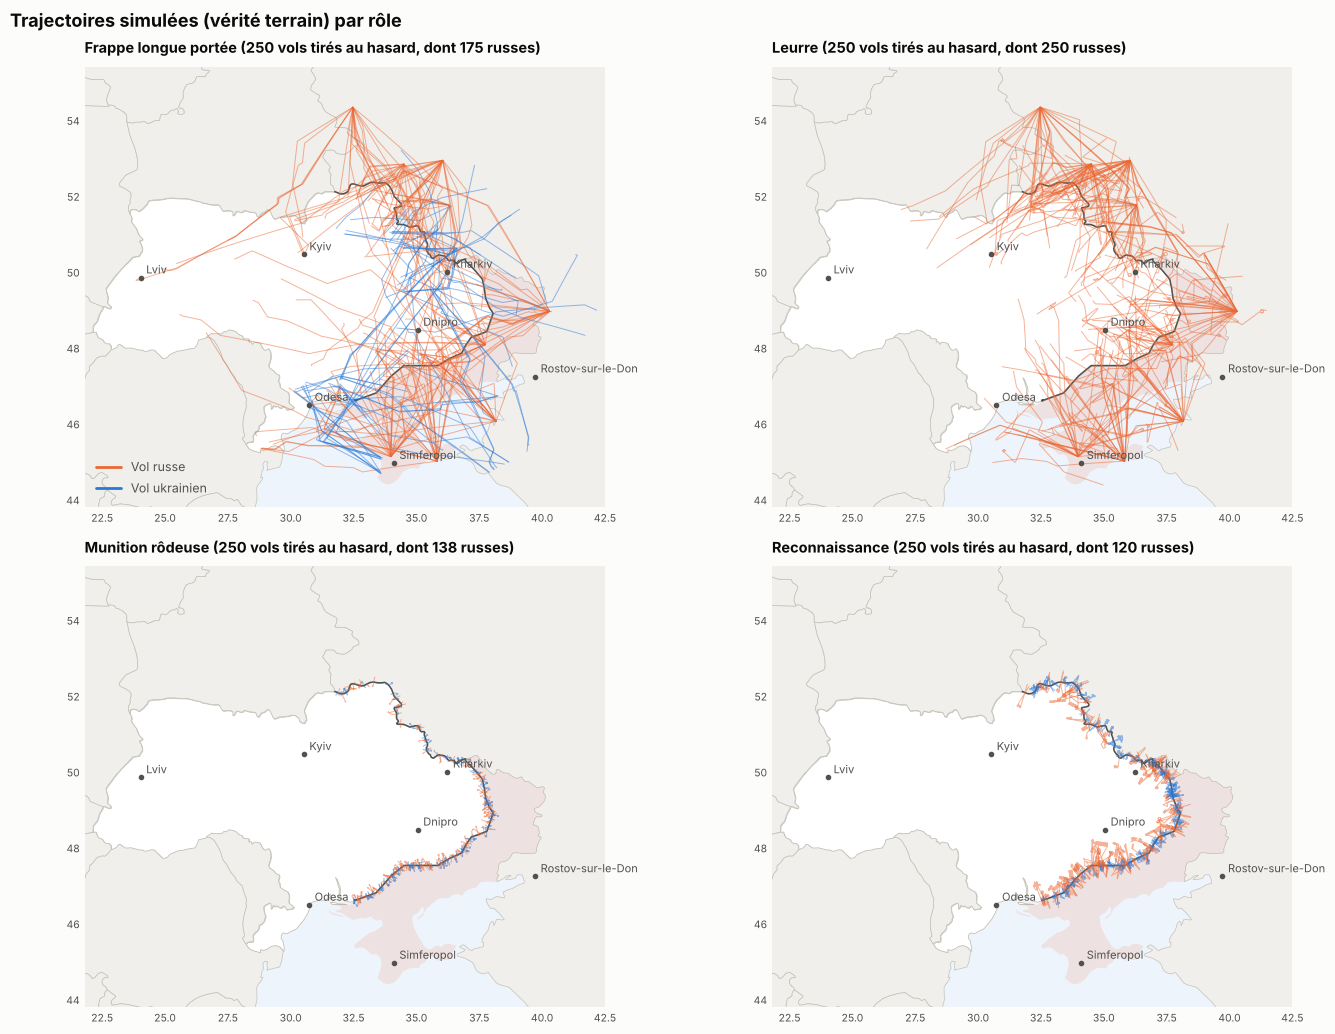

In [8]:
from drone_v2.simulation import vols_vers_points
verite = vols_vers_points(d["vols"])
fig = viz.fig_trajectoires_par_role(theatre, verite, resume)
viz.sauver(fig, "02_trajectoires_par_role_v2")
plt.show()

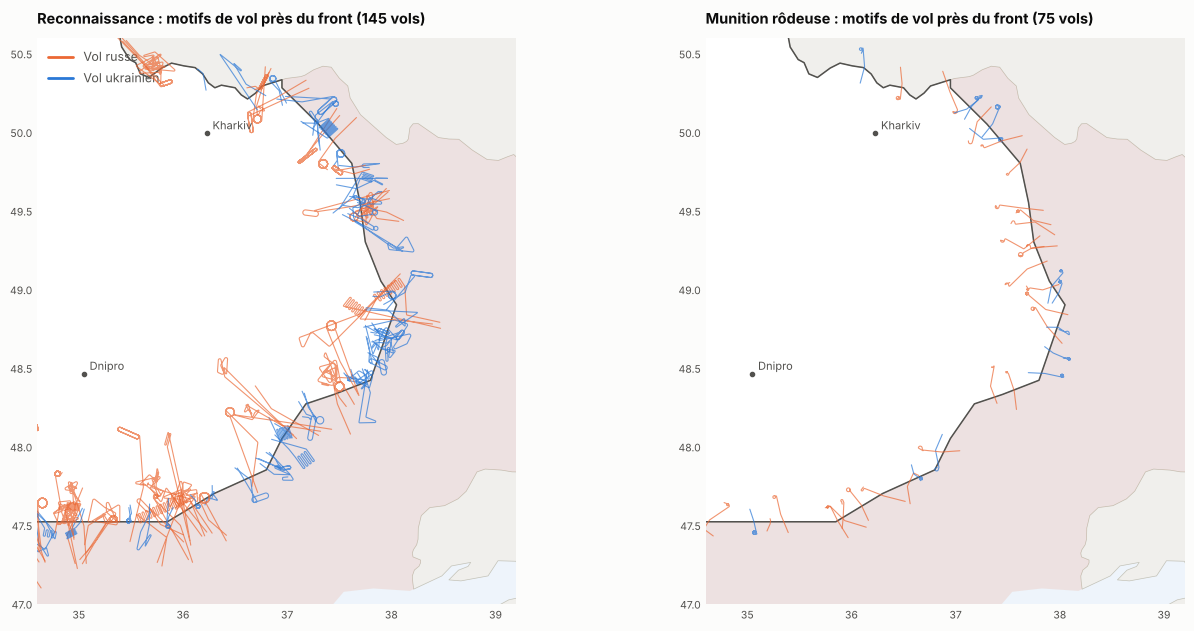

In [9]:
fig = viz.fig_zoom_tactique(theatre, verite, resume)
viz.sauver(fig, "03_zoom_front_tactique_v2")
plt.show()

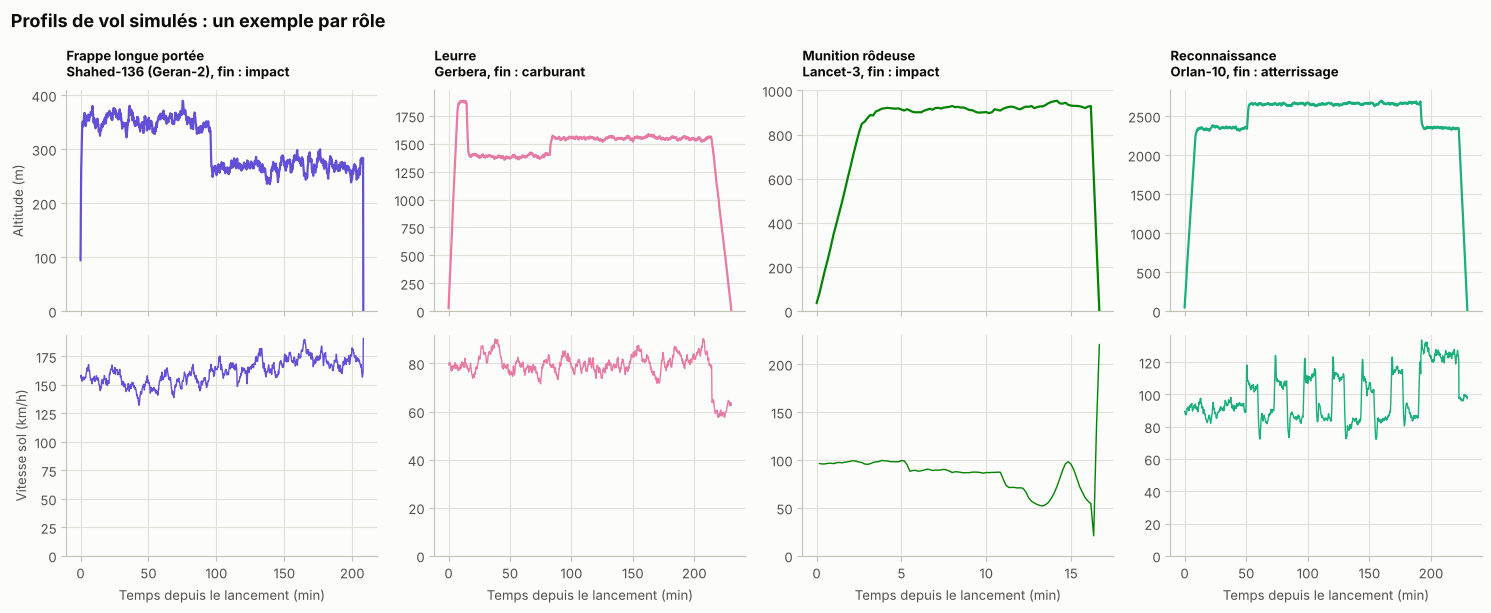

In [10]:
exemples = {}
for v in d["vols"]:
    if v.role not in exemples and v.jour >= 3 and v.fin in ("impact", "atterrissage", "carburant"):
        exemples[v.role] = v
exemples = {r: exemples[r] for r in viz.COULEUR_ROLE}
fig = viz.fig_profils(exemples)
viz.sauver(fig, "04_profils_vol_v2")
plt.show()

## 5. Cohérence avec les sources

Garde-fou contre les valeurs inventées : les vols simulés doivent rester dans les fourchettes publiées. Le contrôle porte sur la vitesse de croisière, le rayon d'action (éloignement maximal par rapport au point de lancement) et l'endurance (95e centile des durées de vol). Les drones brouillés sont exclus du contrôle de portée car ils dérivent hors de contrôle.

In [11]:
c = catalogue.set_index("modele")
nominaux = resume[resume.fin != "brouille"]
controle = nominaux.groupby("modele").agg(
    vols=("drone_id", "size"),
    v_croisiere_min=("v_croisiere_kmh", "min"), v_croisiere_max=("v_croisiere_kmh", "max"),
    eloignement_max_km=("eloignement_max_km", "max"),
    duree_p95_min=("duree_min", lambda x: np.percentile(x, 95)), duree_max_min=("duree_min", "max"))
c = c.reindex(controle.index)
controle["vitesse_dans_fourchette"] = ((controle.v_croisiere_min >= c.v_croisiere_min)
                                       & (controle.v_croisiere_max <= c.v_croisiere_max))
controle["portee_publiee_km"] = c.portee_km
controle["eloignement_sur_portee"] = controle.eloignement_max_km / c.portee_km
controle["endurance_publiee_min"] = c.endurance_h * 60
controle["duree_p95_sur_endurance"] = controle.duree_p95_min / controle.endurance_publiee_min
display(controle)
assert controle.vitesse_dans_fourchette.all()
assert (controle.eloignement_sur_portee <= 1.0).all()
assert (controle.duree_p95_sur_endurance.dropna() <= 1.0).all()
print("Contrôles validés : vitesses de croisière, rayons d'action et endurances (95e centile) "
      "restent dans les valeurs publiées.")
ratio_max = controle.duree_max_min / controle.endurance_publiee_min
print(f"Plus long vol rapporté à l'endurance publiée : {ratio_max.max():.2f} ({ratio_max.idxmax()})")

,vols,v_croisiere_min,v_croisiere_max,eloignement_max_km,duree_p95_min,duree_max_min,vitesse_dans_fourchette,portee_publiee_km,eloignement_sur_portee,endurance_publiee_min,duree_p95_sur_endurance
modele,,,,,,,,,,,
A1-SM Furia,358,65.011,84.946,48.598,152.192,180.667,True,50,0.972,180.000,0.846
An-196 Liutyi,272,150.402,199.736,960.720,279.567,357.667,True,2000,0.480,NaN,NaN
Gerbera,1063,90.089,129.930,594.992,322.933,392.500,True,600,0.992,NaN,NaN
Lancet-3,493,80.019,109.982,38.023,36.233,54.833,True,40,0.951,60.000,0.604
Leleka-100,421,65.003,79.957,39.767,129.333,153.333,True,45,0.884,150.000,0.862
Orlan-10,499,90.038,119.962,94.251,312.250,357.167,True,120,0.785,960.000,0.325
Shahed-136 (Geran-2),1589,150.012,184.966,1 182.813,286.967,521.833,True,2000,0.591,720.000,0.399
Supercam S350,400,75.233,119.607,71.169,212.550,245.500,True,100,0.712,270.000,0.787
UJ-22 Airborne,175,120.001,139.817,592.940,303.933,344.000,True,800,0.741,420.000,0.724


Contrôles validés : vitesses de croisière, rayons d'action et endurances (95e centile) restent dans les valeurs publiées.
Plus long vol rapporté à l'endurance publiée : 1.21 (Valkyria)


Les rares vols qui dépassent l'endurance publiée sont ceux de petits drones lents volant par vent soutenu : le vent réduit la vitesse sol et allonge le vol, alors que la durée de mission planifiée reste dans les valeurs publiées.

La vitesse **mesurée** par le radar diffère de la vitesse de croisière : elle inclut le vent, les phases de montée, de patrouille et de piqué, et le bruit de mesure. Les deux graphiques comparent ces mesures aux fourchettes du catalogue.

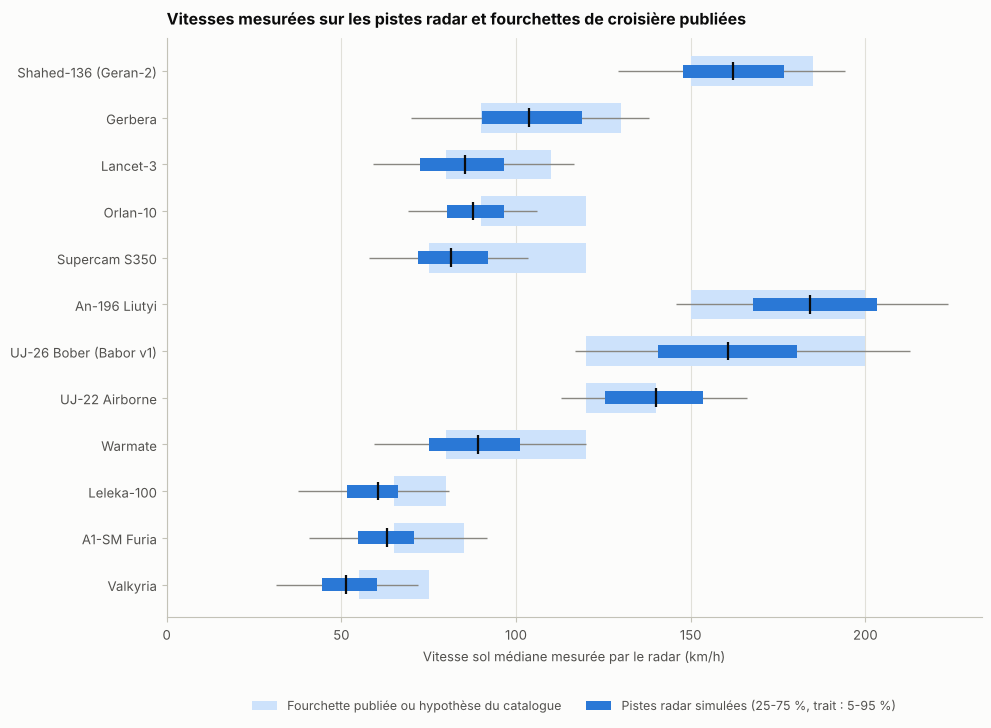

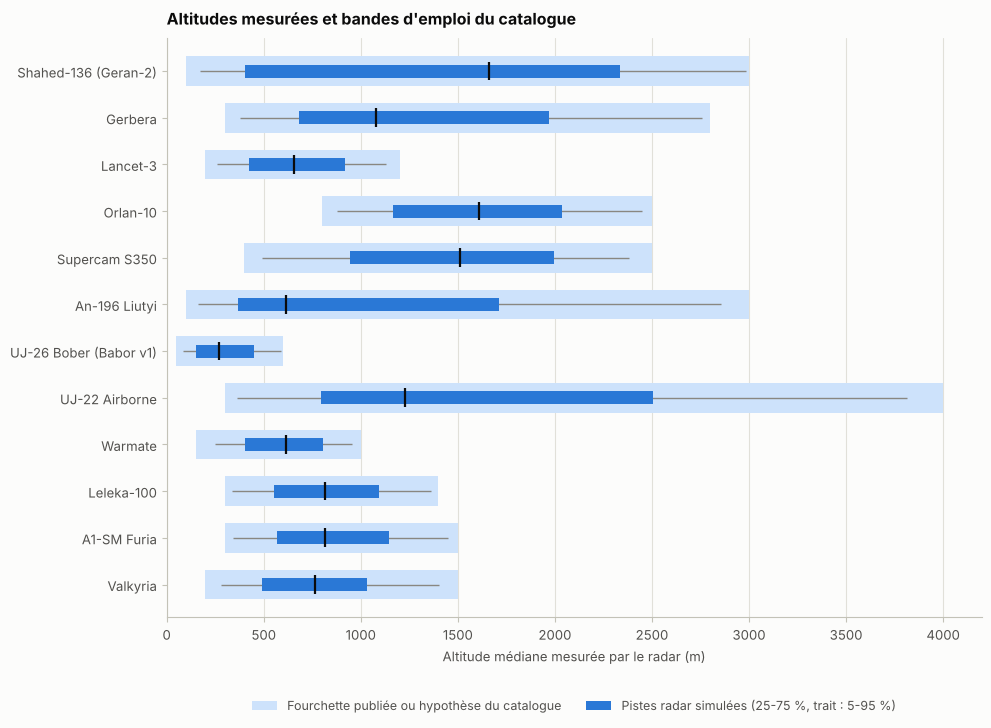

In [12]:
fig = viz.fig_coherence_osint(variables, catalogue, "vitesse_med", "v_croisiere_min", "v_croisiere_max",
                              "Vitesse sol médiane mesurée par le radar (km/h)",
                              "Vitesses mesurées sur les pistes radar et fourchettes de croisière publiées")
viz.sauver(fig, "05_coherence_vitesses_v2")
plt.show()
fig = viz.fig_coherence_osint(variables, catalogue, "alt_med", "alt_simulee_min", "alt_simulee_max",
                              "Altitude médiane mesurée par le radar (m)",
                              "Altitudes mesurées et bandes d'emploi du catalogue")
viz.sauver(fig, "06_coherence_altitudes_v2")
plt.show()

## 6. Observation radar

Le classifieur ne voit jamais la vérité terrain : il reçoit uniquement des plots radar (temps, position et altitude bruitées). La portée de détection dépend de l'altitude (horizon radioélectrique) et de la taille du drone (SER) : un drone qui vole bas est perdu entre deux radars, et son vol se découpe en plusieurs pistes.

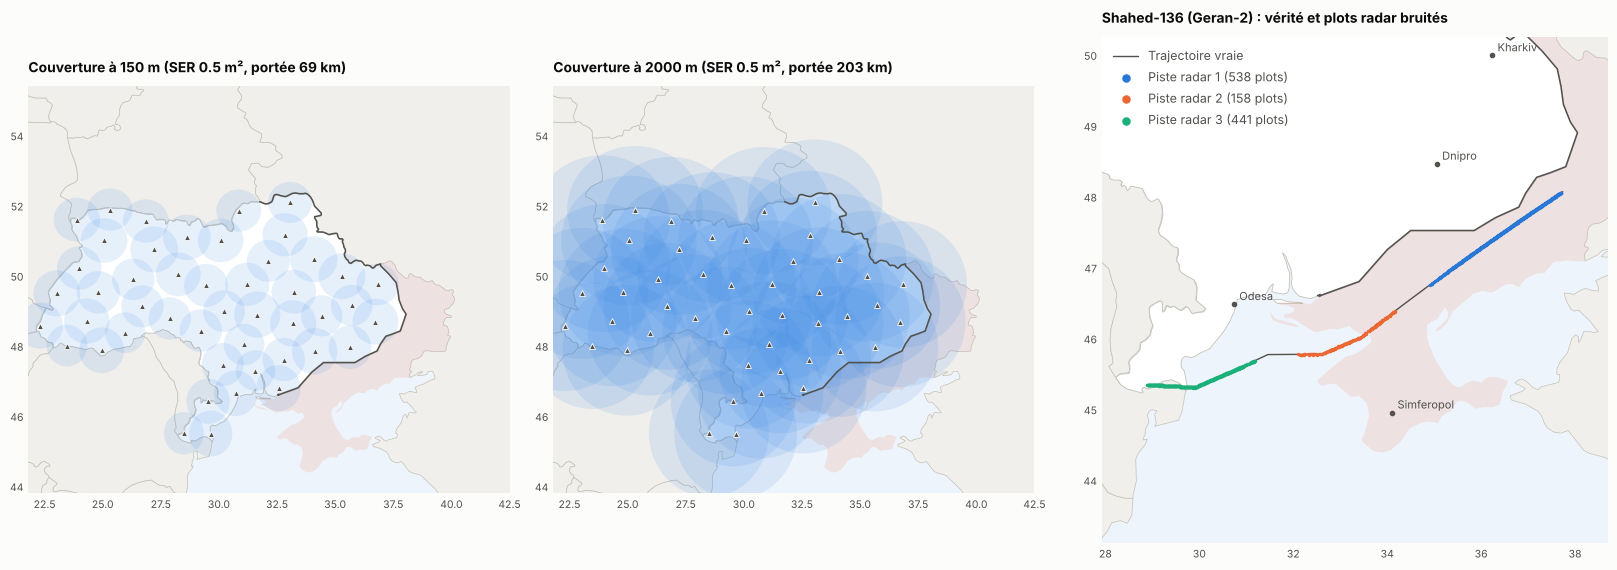

In [13]:
fragmentes = pistes[(pistes.nb_fragments >= 3) & (pistes.role == "Frappe longue portée")]
vol_id = fragmentes.sort_values("drone_id").drone_id.iloc[0]
vol = next(v for v in d["vols"] if v.drone_id == vol_id)
plots_vol = [g for _, g in plots[plots.piste_id.str.startswith(vol_id + "_P")].groupby("piste_id")]
fig = viz.fig_radar(theatre, radar, vol, plots_vol)
viz.sauver(fig, "07_observation_radar_v2")
plt.show()

In [14]:
observation = pistes.groupby("modele").agg(
    pistes=("piste_id", "size"), plots_par_piste=("n_plots", "median"),
    part_vols_fragmentes=("nb_fragments", lambda x: float((x > 1).mean())),
    decollage_observe=("vol_debut_observe", "mean"))
observation["vols_jamais_detectes"] = resume.groupby("modele").nb_pistes.apply(lambda x: float((x == 0).mean()))
display(observation)

,pistes,plots_par_piste,part_vols_fragmentes,decollage_observe,vols_jamais_detectes
modele,,,,,
A1-SM Furia,477,439.000,0.329,0.153,0.005
An-196 Liutyi,336,510.000,0.074,0.387,0.003
Gerbera,1385,764.000,0.100,0.000,0.062
Lancet-3,598,126.000,0.000,0.080,0.008
Leleka-100,524,427.500,0.273,0.134,0.009
Orlan-10,608,1 010.500,0.000,0.026,0.000
Shahed-136 (Geran-2),1951,539.000,0.087,0.000,0.013
Supercam S350,468,754.000,0.006,0.028,0.000
UJ-22 Airborne,196,662.000,0.041,0.474,0.000


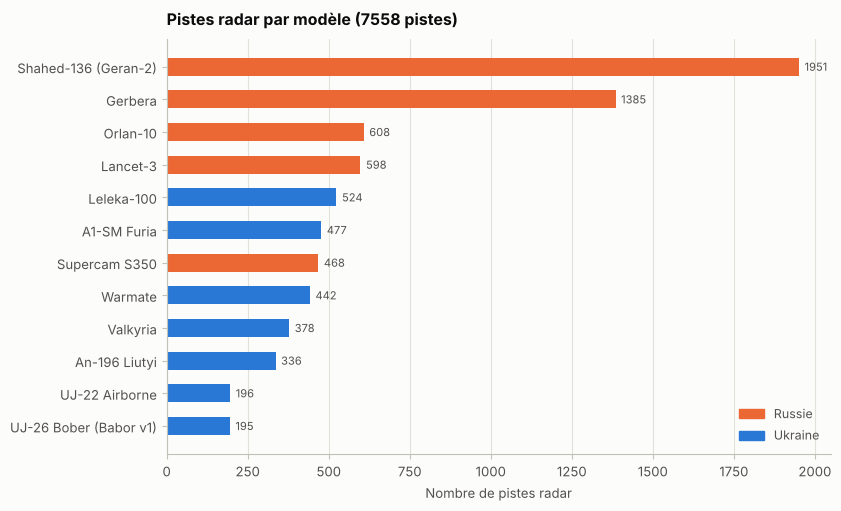

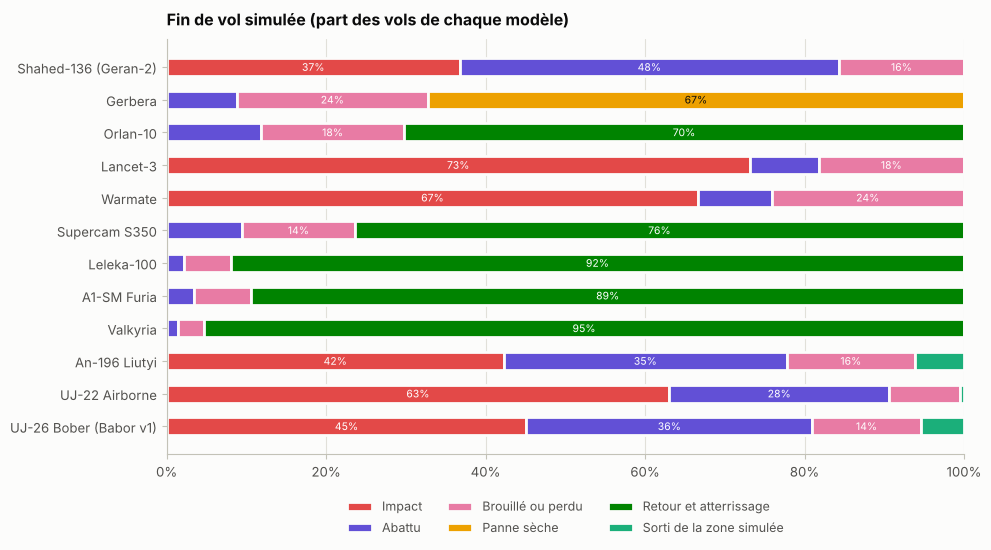

In [15]:
fig = viz.fig_volumes(pistes)
viz.sauver(fig, "08_volumes_v2")
plt.show()
fig = viz.fig_fins_de_vol(resume)
viz.sauver(fig, "09_fins_de_vol_v2")
plt.show()

## 7. Variables par piste

Chaque piste radar est résumée par des variables regroupées en familles. Elles sont toutes calculées à partir des plots observés, après rééchantillonnage régulier et lissage (filtre de Savitzky-Golay) :

* **observation** : durée, nombre de plots, taux de détection ;
* **cinématique** : vitesses (moyenne, quantiles, variabilité), accélération, taux de virage, rectitude, rayon de giration, compacité ;
* **altitude** : niveaux, dispersion, vitesses verticales, descente finale ;
* **géographie** : distance signée à la ligne de séparation (positive côté ukrainien), part du temps côté ukrainien, cap net, distance à la ville la plus proche en fin de piste ;
* **temps** : heure de la première détection (encodage circulaire).

Aucune variable n'utilise une grandeur interne du simulateur (vitesse vraie, modèle, cible, cause de fin).

In [16]:
from drone_v2.variables import FAMILLES, VARIABLES, verifier_absence_de_fuite
verifier_absence_de_fuite(VARIABLES)
display(pd.DataFrame([(f, len(v), ", ".join(v)) for f, v in FAMILLES.items()],
                     columns=["famille", "nombre", "variables"]))
display(variables[VARIABLES].describe().T[["mean", "std", "min", "50%", "max"]])

,famille,nombre,variables
0,observation,3,"duree_min, n_plots, taux_detection"
1,cinematique,17,"longueur_km, deplacement_km, rectitude, vitess..."
2,altitude,10,"alt_moy, alt_med, alt_std, alt_p05, alt_p95, a..."
3,geographie,10,"dist_front_debut_km, dist_front_fin_km, dist_f..."
4,temps,2,"heure_sin, heure_cos"


,mean,std,min,50%,max
duree_min,101.596,72.750,3.333,90.833,473.000
n_plots,566.522,432.293,18.000,499.000,2 738.000
taux_detection,0.880,0.167,0.179,0.947,1.000
longueur_km,199.522,162.830,5.053,164.894,1 298.547
deplacement_km,138.382,159.551,0.126,65.065,1 149.363
rectitude,0.643,0.376,0.000,0.849,0.999
vitesse_moy,112.219,44.088,21.741,100.704,250.945
vitesse_med,111.667,44.957,21.459,101.326,253.792
vitesse_std,17.062,5.568,6.584,16.093,61.649
vitesse_p10,91.845,45.956,9.004,79.559,227.404


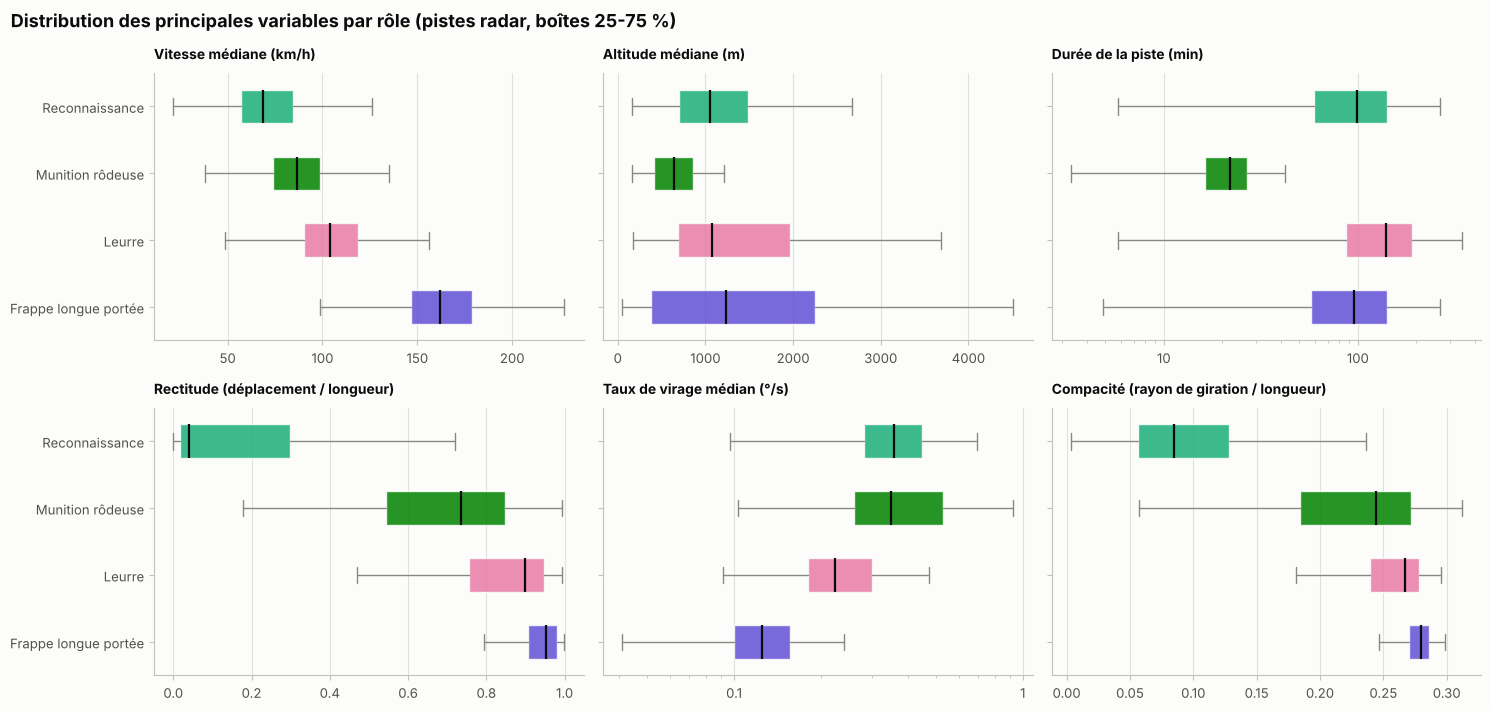

In [17]:
fig = viz.fig_distributions(variables)
viz.sauver(fig, "10_distributions_variables_v2")
plt.show()

## 8. Sauvegarde

Les tables légères sont versionnées dans le dépôt. Les plots radar complets et la vérité terrain point par point (plusieurs centaines de Mo) sont régénérés à l'identique à partir de la graine si besoin.

In [18]:
donnees.sauvegarder(d)
for f in sorted(config.GENEREES.iterdir()):
    versionne = f.name not in ("plots_v2.parquet", "verite_v2.parquet")
    print(f"{f.name:32s} {f.stat().st_size / 1e6:7.2f} Mo  {'versionné' if versionne else 'régénérable (non versionné)'}")

pistes_v2.csv.gz                    0.34 Mo  versionné
plots_echantillon_v2.parquet        1.98 Mo  versionné
plots_v2.parquet                  101.91 Mo  régénérable (non versionné)
radars_v2.csv                       0.00 Mo  versionné
variables_v2.csv.gz                 1.31 Mo  versionné
verite_v2.parquet                 137.19 Mo  régénérable (non versionné)
vols_v2.csv.gz                      0.33 Mo  versionné
